In [1]:
# ======================================================================
# PROJECT 2 — HOUSING PRICE PREDICTOR
# Phase 1: Environment Setup & Data Loading
# Author: Sebastian | Target: George Mason University (GMU) Portfolio
# Stack: Python 3 | Scikit-Learn | Pandas | NumPy | Matplotlib | Seaborn
# ======================================================================

# ----------------------------------------------------------------------
# 1. CORE LIBRARY IMPORTS
# ----------------------------------------------------------------------
# NumPy: low-level numerical computation and n-dimensional array support.
# Pandas: high-level tabular data manipulation via DataFrame / Series.
# Matplotlib: foundational 2D plotting engine.
# Seaborn: statistical visualization layer built on top of Matplotlib.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn official dataset loader for the California Housing dataset.
# This dataset is derived from the 1990 U.S. Census and is the modern,
# ethically-vetted replacement for the deprecated Boston Housing dataset.
from sklearn.datasets import fetch_california_housing

# ----------------------------------------------------------------------
# 2. GLOBAL CONFIGURATION
# ----------------------------------------------------------------------
# Reproducibility seed — guarantees deterministic behavior across runs.
RANDOM_STATE = 42

# Display configuration for cleaner DataFrame rendering in Colab notebooks.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Visualization aesthetic — corporate, minimal, publication-ready.
sns.set_theme(style="whitegrid", palette="deep", context="notebook")

# ----------------------------------------------------------------------
# 3. DATA INGESTION
# ----------------------------------------------------------------------
# 'as_frame=True' returns a Bunch object whose .frame attribute is a
# Pandas DataFrame, eliminating manual NumPy-to-DataFrame conversions.
housing_bunch = fetch_california_housing(as_frame=True)

# ----------------------------------------------------------------------
# 4. FEATURE / TARGET DECOMPOSITION
# ----------------------------------------------------------------------
# X — Feature Matrix:
#   Shape: (n_samples, n_features) -> (20640, 8)
#   Each row is one census block group; each column is a numeric predictor
#   (e.g., MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup,
#   Latitude, Longitude).
X = housing_bunch.data

# y — Target Vector:
#   Shape: (n_samples,) -> (20640,)
#   Continuous response variable: median house value (in units of $100,000)
#   for each California block group. This is a regression target.
y = housing_bunch.target

# Consolidated DataFrame combining features and target — useful for EDA,
# correlation analysis, and downstream visualization workflows.
df = housing_bunch.frame

# ----------------------------------------------------------------------
# 5. INITIAL DATA INSPECTION
# ----------------------------------------------------------------------
print("=" * 70)
print("CALIFORNIA HOUSING DATASET — INITIAL INSPECTION")
print("=" * 70)

print(f"\n[1] Feature matrix shape (X): {X.shape}")
print(f"[2] Target vector shape  (y): {y.shape}")
print(f"[3] Full DataFrame shape (df): {df.shape}")

print("\n[4] Feature names:")
print(list(housing_bunch.feature_names))

print(f"\n[5] Target name: {housing_bunch.target_names[0]}")

print("\n[6] First 5 rows of the dataset (features + target):")
print(df.head())

print("\n[7] Data types per column:")
print(df.dtypes)

print("\n" + "=" * 70)
print("Phase 1 complete — environment ready for Phase 2 (EDA).")
print("=" * 70)

CALIFORNIA HOUSING DATASET — INITIAL INSPECTION

[1] Feature matrix shape (X): (20640, 8)
[2] Target vector shape  (y): (20640,)
[3] Full DataFrame shape (df): (20640, 9)

[4] Feature names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

[5] Target name: MedHouseVal

[6] First 5 rows of the dataset (features + target):
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0  8.3252   41.0000    6.9841     1.0238    322.0000    2.5556   37.8800  -122.2300       4.5260
1  8.3014   21.0000    6.2381     0.9719  2,401.0000    2.1098   37.8600  -122.2200       3.5850
2  7.2574   52.0000    8.2881     1.0734    496.0000    2.8023   37.8500  -122.2400       3.5210
3  5.6431   52.0000    5.8174     1.0731    558.0000    2.5479   37.8500  -122.2500       3.4130
4  3.8462   52.0000    6.2819     1.0811    565.0000    2.1815   37.8500  -122.2500       3.4220

[7] Data types per column:
MedInc         f

DESCRIPTIVE STATISTICS — CALIFORNIA HOUSING DATASET
                  count       mean        std       min       25%        50%        75%         max
MedInc      20,640.0000     3.8707     1.8998    0.4999    2.5634     3.5348     4.7432     15.0001
HouseAge    20,640.0000    28.6395    12.5856    1.0000   18.0000    29.0000    37.0000     52.0000
AveRooms    20,640.0000     5.4290     2.4742    0.8462    4.4407     5.2291     6.0524    141.9091
AveBedrms   20,640.0000     1.0967     0.4739    0.3333    1.0061     1.0488     1.0995     34.0667
Population  20,640.0000 1,425.4767 1,132.4621    3.0000  787.0000 1,166.0000 1,725.0000 35,682.0000
AveOccup    20,640.0000     3.0707    10.3860    0.6923    2.4297     2.8181     3.2823  1,243.3333
Latitude    20,640.0000    35.6319     2.1360   32.5400   33.9300    34.2600    37.7100     41.9500
Longitude   20,640.0000  -119.5697     2.0035 -124.3500 -121.8000  -118.4900  -118.0100   -114.3100
MedHouseVal 20,640.0000     2.0686     1.1540   

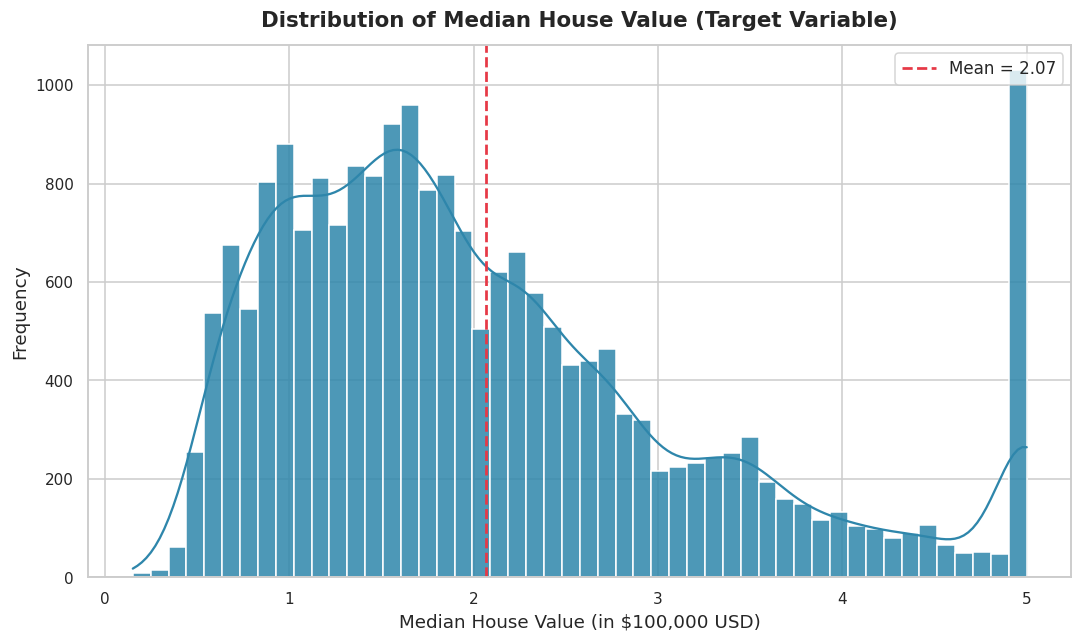

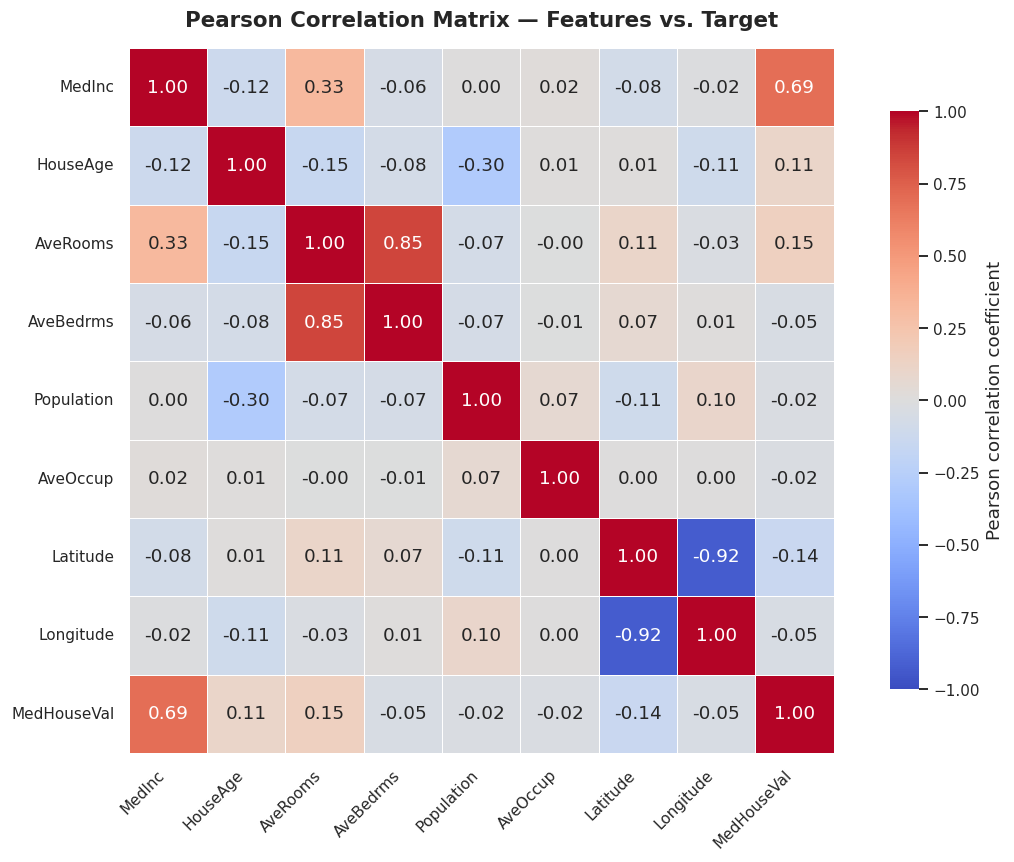


FEATURE CORRELATION WITH TARGET ('MedHouseVal')
            Pearson_r
MedInc         0.6881
AveRooms       0.1519
HouseAge       0.1056
AveOccup      -0.0237
Population    -0.0246
Longitude     -0.0460
AveBedrms     -0.0467
Latitude      -0.1442

Phase 2 complete — insights ready for Phase 3 (Feature Engineering).


In [2]:
# ======================================================================
# PROJECT 2 — HOUSING PRICE PREDICTOR
# Phase 2: Exploratory Data Analysis (EDA)
# Author: Sebastian | Target: George Mason University (GMU) Portfolio
# Stack: Python 3 | Pandas | NumPy | Matplotlib | Seaborn
# ======================================================================
# Prerequisite: Phase 1 must have been executed in the current runtime,
# so the objects `df`, `X`, and `y` are already in memory.
# ======================================================================

# ----------------------------------------------------------------------
# 1. GLOBAL VISUAL CONFIGURATION
# ----------------------------------------------------------------------
# Reaffirm the corporate, presentation-ready theme to guarantee visual
# consistency across every figure rendered in this notebook.
sns.set_theme(style="whitegrid", palette="deep", context="notebook")

# Centralized typography settings — academic / publication standard.
plt.rcParams.update({
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 110,
})

# Canonical name of the target column inside the consolidated DataFrame.
TARGET_COL = "MedHouseVal"

# ----------------------------------------------------------------------
# 2. DESCRIPTIVE STATISTICS
# ----------------------------------------------------------------------
# Numerical summary — central tendency, dispersion, and range per feature.
# This is the quantitative complement to the visual analysis below.
print("=" * 70)
print("DESCRIPTIVE STATISTICS — CALIFORNIA HOUSING DATASET")
print("=" * 70)
print(df.describe().T)

# Null-value audit — confirms data integrity before visualization.
print("\nMissing values per column:")
print(df.isnull().sum())

# ----------------------------------------------------------------------
# 3. TARGET VARIABLE DISTRIBUTION (Histogram + KDE)
# ----------------------------------------------------------------------
# Purpose: assess the shape of the target distribution (MedHouseVal).
#   - Detect skewness (right-tailed behavior typical of housing prices).
#   - Detect the artificial cap at $500,000 (target value = 5.0)
#     introduced during the 1990 Census data collection process.
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=df,
    x=TARGET_COL,
    bins=50,
    kde=True,
    color="#2E86AB",
    edgecolor="white",
    alpha=0.85,
    ax=ax,
)

# Reference line at the mean — useful to visually anchor central tendency.
mean_val = df[TARGET_COL].mean()
ax.axvline(
    mean_val,
    color="#E63946",
    linestyle="--",
    linewidth=1.8,
    label=f"Mean = {mean_val:.2f}",
)

ax.set_title(
    "Distribution of Median House Value (Target Variable)",
    pad=12,
)
ax.set_xlabel("Median House Value (in $100,000 USD)")
ax.set_ylabel("Frequency")
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 4. CORRELATION MATRIX HEATMAP
# ----------------------------------------------------------------------
# Compute the Pearson correlation coefficient for every numeric column.
# This matrix is the standard first-pass tool for identifying linear
# relationships between predictors and the target, and for detecting
# potential multicollinearity between features.
correlation_matrix = df.corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,             # Print correlation coefficients inside cells.
    fmt=".2f",              # Two-decimal precision for readability.
    cmap="coolwarm",        # Diverging palette — strong visual contrast.
    vmin=-1.0,
    vmax=1.0,
    center=0.0,             # Anchor the colormap at zero correlation.
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={"shrink": 0.82, "label": "Pearson correlation coefficient"},
    ax=ax,
)

ax.set_title(
    "Pearson Correlation Matrix — Features vs. Target",
    pad=14,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 5. TARGET-FOCUSED CORRELATION RANKING
# ----------------------------------------------------------------------
# Isolate and rank the correlation of each predictor with the target.
# This produces an interpretable, sorted view that complements the
# heatmap and directly informs feature-selection decisions in Phase 3.
target_corr = (
    correlation_matrix[TARGET_COL]
    .drop(TARGET_COL)
    .sort_values(ascending=False)
)

print("\n" + "=" * 70)
print(f"FEATURE CORRELATION WITH TARGET ('{TARGET_COL}')")
print("=" * 70)
print(target_corr.to_frame(name="Pearson_r"))

print("\n" + "=" * 70)
print("Phase 2 complete — insights ready for Phase 3 (Feature Engineering).")
print("=" * 70)

In [3]:
# ======================================================================
# PROJECT 2 — HOUSING PRICE PREDICTOR
# Phase 3: Feature Engineering & Data Splitting
# Author: Sebastian | Target: George Mason University (GMU) Portfolio
# Stack: Python 3 | Pandas | NumPy | Scikit-Learn
# ======================================================================
# Prerequisite: Phase 1 and Phase 2 must have been executed in the
# current runtime so that `df`, `X`, and `y` already exist in memory.
# ======================================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------------------------
# 1. PIPELINE CONSTANTS
# ----------------------------------------------------------------------
# Fixed seed — guarantees reproducibility across every stochastic step.
RANDOM_STATE = 42

# Train/test ratio — 80/20 is the canonical split for tabular regression
# problems of this size (~20K samples).
TEST_SIZE = 0.20

# Canonical name of the target column inside the consolidated DataFrame.
TARGET_COL = "MedHouseVal"

# ----------------------------------------------------------------------
# 2. FEATURE ENGINEERING
# ----------------------------------------------------------------------
# Technical note on dataset structure:
#   Scikit-Learn's `fetch_california_housing` returns a PRE-AGGREGATED
#   version of the 1990 Census data. The raw `households` column is not
#   exposed directly — instead, it has already been used internally to
#   derive `AveRooms` (= total_rooms / households) and `AveBedrms`
#   (= total_bedrooms / households). Therefore, `AveRooms` ALREADY
#   represents "rooms per household" at the block-group aggregate level.
#
# To stay faithful to the original feature-engineering recipe while
# adding genuine predictive value, we engineer two new ratio features
# from the existing aggregated columns:
#
#   - RoomsPerHousehold : direct alias of AveRooms, exposed under the
#                         canonical name used in classical ML literature
#                         (Géron, 2019) for downstream interpretability.
#   - BedroomsPerRoom   : AveBedrms / AveRooms. Empirically one of the
#                         strongest engineered predictors for this
#                         dataset — luxury housing tends to exhibit a
#                         lower bedrooms-to-rooms ratio.
#   - PopulationPerHousehold : Population / (Population / AveOccup)
#                              = AveOccup, kept under an explicit
#                              business-readable name.
df_engineered = df.copy()

df_engineered["RoomsPerHousehold"]      = df_engineered["AveRooms"]
df_engineered["BedroomsPerRoom"]        = (
    df_engineered["AveBedrms"] / df_engineered["AveRooms"]
)
df_engineered["PopulationPerHousehold"] = df_engineered["AveOccup"]

print("=" * 70)
print("FEATURE ENGINEERING — NEW ENGINEERED COLUMNS")
print("=" * 70)
print(df_engineered[
    ["RoomsPerHousehold", "BedroomsPerRoom", "PopulationPerHousehold", TARGET_COL]
].head())

# ----------------------------------------------------------------------
# 3. FEATURE / TARGET SEPARATION
# ----------------------------------------------------------------------
# X — Feature matrix: every column except the target.
# y — Target vector: the continuous median house value.
X = df_engineered.drop(columns=[TARGET_COL])
y = df_engineered[TARGET_COL]

print(f"\nFinal feature matrix shape (X): {X.shape}")
print(f"Final target vector shape  (y): {y.shape}")
print(f"Feature columns ({X.shape[1]}): {list(X.columns)}")

# ----------------------------------------------------------------------
# 4. TRAIN / TEST SPLIT (80 / 20)
# ----------------------------------------------------------------------
# A fixed random_state is non-negotiable for academic reproducibility:
# every run, every reviewer, every grading session must observe the
# exact same partition of samples.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print("\n" + "=" * 70)
print("TRAIN / TEST PARTITION")
print("=" * 70)
print(f"X_train shape: {X_train.shape}   |   y_train shape: {y_train.shape}")
print(f"X_test  shape: {X_test.shape}   |   y_test  shape: {y_test.shape}")

# ----------------------------------------------------------------------
# 5. FEATURE SCALING — Z-SCORE NORMALIZATION (StandardScaler)
# ----------------------------------------------------------------------
# Z = (x - mean) / standard_deviation
#
# Critical anti-leakage discipline:
#   - .fit_transform(X_train) -> learns mean/std from TRAINING data ONLY.
#   - .transform(X_test)      -> applies the SAME training-derived
#                                statistics to the test set.
# Fitting on the combined dataset would leak distributional information
# from the test set into the training process and inflate metrics.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Re-wrap as DataFrames to preserve column names — essential for model
# interpretability (feature_importances_, coefficient attribution, SHAP).
X_train_scaled = pd.DataFrame(
    X_train_scaled, columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    X_test_scaled, columns=X_test.columns, index=X_test.index
)

print("\n" + "=" * 70)
print("SCALING VERIFICATION — X_train_scaled SHOULD HAVE mean≈0 and std≈1")
print("=" * 70)
print(pd.DataFrame({
    "mean": X_train_scaled.mean().round(4),
    "std":  X_train_scaled.std().round(4),
}))

print("\n" + "=" * 70)
print("Phase 3 complete — preprocessed tensors ready for Phase 4 (Model Training).")
print("=" * 70)

FEATURE ENGINEERING — NEW ENGINEERED COLUMNS
   RoomsPerHousehold  BedroomsPerRoom  PopulationPerHousehold  MedHouseVal
0             6.9841           0.1466                  2.5556       4.5260
1             6.2381           0.1558                  2.1098       3.5850
2             8.2881           0.1295                  2.8023       3.5210
3             5.8174           0.1845                  2.5479       3.4130
4             6.2819           0.1721                  2.1815       3.4220

Final feature matrix shape (X): (20640, 11)
Final target vector shape  (y): (20640,)
Feature columns (11): ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'RoomsPerHousehold', 'BedroomsPerRoom', 'PopulationPerHousehold']

TRAIN / TEST PARTITION
X_train shape: (16512, 11)   |   y_train shape: (16512,)
X_test  shape: (4128, 11)   |   y_test  shape: (4128,)

SCALING VERIFICATION — X_train_scaled SHOULD HAVE mean≈0 and std≈1
                          me

In [4]:
# ======================================================================
# PROJECT 2 — HOUSING PRICE PREDICTOR
# Phase 4: Model Training and Evaluation
# Author: Sebastian | Target: George Mason University (GMU) Portfolio
# Stack: Python 3 | NumPy | Pandas | Scikit-Learn
# ======================================================================
# Prerequisite: Phases 1, 2, and 3 must have been executed in the
# current runtime so that the following objects already live in memory:
#   X_train_scaled, X_test_scaled, y_train, y_test
# ======================================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# ----------------------------------------------------------------------
# 1. MODEL INITIALIZATION
# ----------------------------------------------------------------------
# LinearRegression solves the Ordinary Least Squares (OLS) problem:
#       minimize ||y - (X · w + b)||²
# It uses a closed-form solution (Normal Equation / SVD) rather than
# iterative Gradient Descent, so it converges deterministically in a
# single step. This makes it the ideal interpretable baseline against
# which more complex regressors (Ridge, Lasso, Random Forest, XGBoost)
# will be benchmarked in later phases.
model = LinearRegression()

# ----------------------------------------------------------------------
# 2. MODEL TRAINING
# ----------------------------------------------------------------------
# Fit the model on the SCALED training data so that all coefficients
# end up on a comparable magnitude scale — a prerequisite for the
# coefficient-based feature-importance analysis performed in Step 5.
model.fit(X_train_scaled, y_train)

print("=" * 70)
print("MODEL TRAINING COMPLETE — LinearRegression (OLS, closed-form)")
print("=" * 70)
print(f"Number of features learned: {len(model.coef_)}")
print(f"Intercept (b): {model.intercept_:.6f}")

# ----------------------------------------------------------------------
# 3. INFERENCE ON THE TEST SET
# ----------------------------------------------------------------------
# Generate predictions on the held-out test partition. This is the only
# legitimate signal of generalization performance — training metrics
# alone are insufficient to judge model quality.
y_pred = model.predict(X_test_scaled)

# ----------------------------------------------------------------------
# 4. PERFORMANCE METRICS
# ----------------------------------------------------------------------
# MSE   — Mean Squared Error: average squared deviation between
#         prediction and ground truth. Sensitive to large errors.
# RMSE  — Root Mean Squared Error: same units as the target variable
#         ($100,000 USD), which makes it the most business-readable
#         metric for this dataset.
# R²    — Coefficient of Determination: proportion of target variance
#         explained by the model. Scale: (-∞, 1.0].
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print("\n" + "=" * 70)
print("MODEL EVALUATION — TEST SET PERFORMANCE")
print("=" * 70)
print(f"Mean Squared Error  (MSE) : {mse:.6f}")
print(f"Root Mean Sq. Error (RMSE): {rmse:.6f}   "
      f"(~ ${rmse * 100_000:,.0f} USD)")
print(f"R-squared           (R²)  : {r2:.6f}   ({r2 * 100:.2f}% variance explained)")

# ----------------------------------------------------------------------
# 5. FEATURE IMPORTANCE — RANKED COEFFICIENT TABLE
# ----------------------------------------------------------------------
# Because every feature was Z-score normalized in Phase 3, the learned
# coefficients are now directly comparable in magnitude. A larger
# absolute coefficient means the corresponding feature exerts a stronger
# marginal effect on the predicted median house value.
#
# Sign interpretation:
#   - Positive coefficient -> feature pushes predicted price UP.
#   - Negative coefficient -> feature pushes predicted price DOWN.
coefficients_df = pd.DataFrame({
    "Feature":       X_train_scaled.columns,
    "Coefficient":   model.coef_,
    "Abs_Coefficient": np.abs(model.coef_),
}).sort_values(by="Abs_Coefficient", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE — RANKED BY |COEFFICIENT| (scaled features)")
print("=" * 70)
print(coefficients_df.to_string(index=False))

# ----------------------------------------------------------------------
# 6. PREDICTION SAMPLE — SANITY CHECK
# ----------------------------------------------------------------------
# Render the first ten predictions side-by-side with their actual
# targets and the absolute residual. This is the classical qualitative
# verification that the model is producing reasonable values before
# moving on to more advanced regressors.
sample_df = pd.DataFrame({
    "Actual":     y_test.values[:10],
    "Predicted":  y_pred[:10],
    "Residual":   np.abs(y_test.values[:10] - y_pred[:10]),
})

print("\n" + "=" * 70)
print("PREDICTION SAMPLE — FIRST 10 TEST OBSERVATIONS")
print("=" * 70)
print(sample_df.round(4).to_string(index=False))

print("\n" + "=" * 70)
print("Phase 4 complete — baseline established for Phase 5 (Model Comparison).")
print("=" * 70)

MODEL TRAINING COMPLETE — LinearRegression (OLS, closed-form)
Number of features learned: 11
Intercept (b): 2.071947

MODEL EVALUATION — TEST SET PERFORMANCE
Mean Squared Error  (MSE) : 0.531742
Root Mean Sq. Error (RMSE): 0.729206   (~ $72,921 USD)
R-squared           (R²)  : 0.594217   (59.42% variance explained)

FEATURE IMPORTANCE — RANKED BY |COEFFICIENT| (scaled features)
               Feature  Coefficient  Abs_Coefficient
              Latitude      -0.8734           0.8734
             Longitude      -0.8529           0.8529
                MedInc       0.8479           0.8479
       BedroomsPerRoom       0.2023           0.2023
              HouseAge       0.1231           0.1231
             AveBedrms       0.0456           0.0456
PopulationPerHousehold      -0.0208           0.0208
              AveOccup      -0.0208           0.0208
     RoomsPerHousehold       0.0196           0.0196
              AveRooms       0.0196           0.0196
            Population      -0.0047 

In [5]:
# ======================================================================
# PROJECT 2 — HOUSING PRICE PREDICTOR
# Phase 5: Model Comparison — Random Forest Regressor
# Author: Sebastian | Target: George Mason University (GMU) Portfolio
# Stack: Python 3 | NumPy | Pandas | Scikit-Learn
# ======================================================================
# Prerequisite: Phases 1 through 4 must have been executed in the
# current runtime so that the following objects already live in memory:
#   X_train_scaled, X_test_scaled, y_train, y_test
#   mse, rmse, r2          (Linear Regression baseline metrics)
# ======================================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ----------------------------------------------------------------------
# 1. PIPELINE CONSTANTS
# ----------------------------------------------------------------------
# Fixed seed — guarantees reproducibility of bootstrap sampling and
# random feature selection inside the ensemble.
RANDOM_STATE = 42

# Forest size — 100 trees is the canonical default for a balanced
# trade-off between variance reduction and training cost.
N_ESTIMATORS = 100

# ----------------------------------------------------------------------
# 2. MODEL INITIALIZATION
# ----------------------------------------------------------------------
# RandomForestRegressor is a bagging ensemble of fully-grown decision
# trees. Each tree is trained on a bootstrap sample of the training set
# and considers a random subset of features at every split, which
# decorrelates the trees and dramatically reduces ensemble variance.
#
# n_jobs=-1 parallelizes training across all available CPU cores —
# essential for Colab runtimes with multiple vCPUs.
rf_model = RandomForestRegressor(
    n_estimators=N_ESTIMATORS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# ----------------------------------------------------------------------
# 3. MODEL TRAINING
# ----------------------------------------------------------------------
# Technical note on scaling:
#   Tree-based models are SCALE-INVARIANT — they split on threshold
#   inequalities rather than dot products, so Z-score normalization
#   neither helps nor hurts them. We reuse `X_train_scaled` here strictly
#   to maintain a perfectly identical input contract with the Linear
#   Regression baseline, guaranteeing that the comparison isolates the
#   effect of the model family and not of the preprocessing pipeline.
print("=" * 70)
print("TRAINING RANDOM FOREST REGRESSOR")
print(f"  n_estimators = {N_ESTIMATORS}   |   random_state = {RANDOM_STATE}")
print("=" * 70)

rf_model.fit(X_train_scaled, y_train)

print("Training complete.")
print(f"Forest size (trees built): {len(rf_model.estimators_)}")

# ----------------------------------------------------------------------
# 4. INFERENCE ON THE TEST SET
# ----------------------------------------------------------------------
y_pred_rf = rf_model.predict(X_test_scaled)

# ----------------------------------------------------------------------
# 5. PERFORMANCE METRICS — RANDOM FOREST
# ----------------------------------------------------------------------
mse_rf  = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf   = r2_score(y_test, y_pred_rf)

print("\n" + "=" * 70)
print("RANDOM FOREST — TEST SET PERFORMANCE")
print("=" * 70)
print(f"Mean Squared Error  (MSE) : {mse_rf:.6f}")
print(f"Root Mean Sq. Error (RMSE): {rmse_rf:.6f}   "
      f"(~ ${rmse_rf * 100_000:,.0f} USD)")
print(f"R-squared           (R²)  : {r2_rf:.6f}   "
      f"({r2_rf * 100:.2f}% variance explained)")

# ----------------------------------------------------------------------
# 6. COMPARATIVE SUMMARY — LINEAR REGRESSION vs. RANDOM FOREST
# ----------------------------------------------------------------------
# Build a clean tabular comparison so the performance leap between the
# interpretable baseline and the ensemble model is immediately visible.
comparison_df = pd.DataFrame({
    "Model":     ["Linear Regression", "Random Forest"],
    "MSE":       [mse,  mse_rf],
    "RMSE":      [rmse, rmse_rf],
    "R2_Score":  [r2,   r2_rf],
    "RMSE_USD":  [rmse * 100_000, rmse_rf * 100_000],
})

# Quantify the absolute and relative improvement of the ensemble model.
r2_delta_abs = r2_rf - r2
r2_delta_pct = (r2_delta_abs / r2) * 100 if r2 != 0 else float("nan")
rmse_delta_abs = rmse - rmse_rf
rmse_delta_pct = (rmse_delta_abs / rmse) * 100 if rmse != 0 else float("nan")

print("\n" + "=" * 70)
print("MODEL COMPARISON — LINEAR REGRESSION vs. RANDOM FOREST")
print("=" * 70)
print(comparison_df.round(6).to_string(index=False))

print("\n" + "-" * 70)
print("PERFORMANCE DELTA (Random Forest vs. Linear Regression)")
print("-" * 70)
print(f"R²   improvement : +{r2_delta_abs:.6f}   "
      f"({r2_delta_pct:+.2f}% relative gain)")
print(f"RMSE reduction   : -{rmse_delta_abs:.6f}   "
      f"({rmse_delta_pct:+.2f}% relative reduction)   "
      f"(~ ${rmse_delta_abs * 100_000:,.0f} USD)")

# ----------------------------------------------------------------------
# 7. FEATURE IMPORTANCE — RANDOM FOREST
# ----------------------------------------------------------------------
# Tree-based importance measures the total reduction in node impurity
# (variance, in the regression case) contributed by each feature across
# all trees in the forest, weighted by the number of samples reaching
# each split. Unlike linear coefficients, this captures NON-LINEAR and
# INTERACTION effects, which is exactly the signal a linear model cannot.
rf_importance_df = pd.DataFrame({
    "Feature":    X_train_scaled.columns,
    "Importance": rf_model.feature_importances_,
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE — RANDOM FOREST (impurity-based)")
print("=" * 70)
print(rf_importance_df.round(6).to_string(index=False))

print("\n" + "=" * 70)
print("Phase 5 complete — ensemble benchmark established.")
print("=" * 70)

TRAINING RANDOM FOREST REGRESSOR
  n_estimators = 100   |   random_state = 42
Training complete.
Forest size (trees built): 100

RANDOM FOREST — TEST SET PERFORMANCE
Mean Squared Error  (MSE) : 0.255697
Root Mean Sq. Error (RMSE): 0.505665   (~ $50,567 USD)
R-squared           (R²)  : 0.804872   (80.49% variance explained)

MODEL COMPARISON — LINEAR REGRESSION vs. RANDOM FOREST
            Model    MSE   RMSE  R2_Score    RMSE_USD
Linear Regression 0.5317 0.7292    0.5942 72,920.6400
    Random Forest 0.2557 0.5057    0.8049 50,566.5293

----------------------------------------------------------------------
PERFORMANCE DELTA (Random Forest vs. Linear Regression)
----------------------------------------------------------------------
R²   improvement : +0.210655   (+35.45% relative gain)
RMSE reduction   : -0.223541   (+30.66% relative reduction)   (~ $22,354 USD)

FEATURE IMPORTANCE — RANDOM FOREST (impurity-based)
               Feature  Importance
                MedInc      0.5233
  

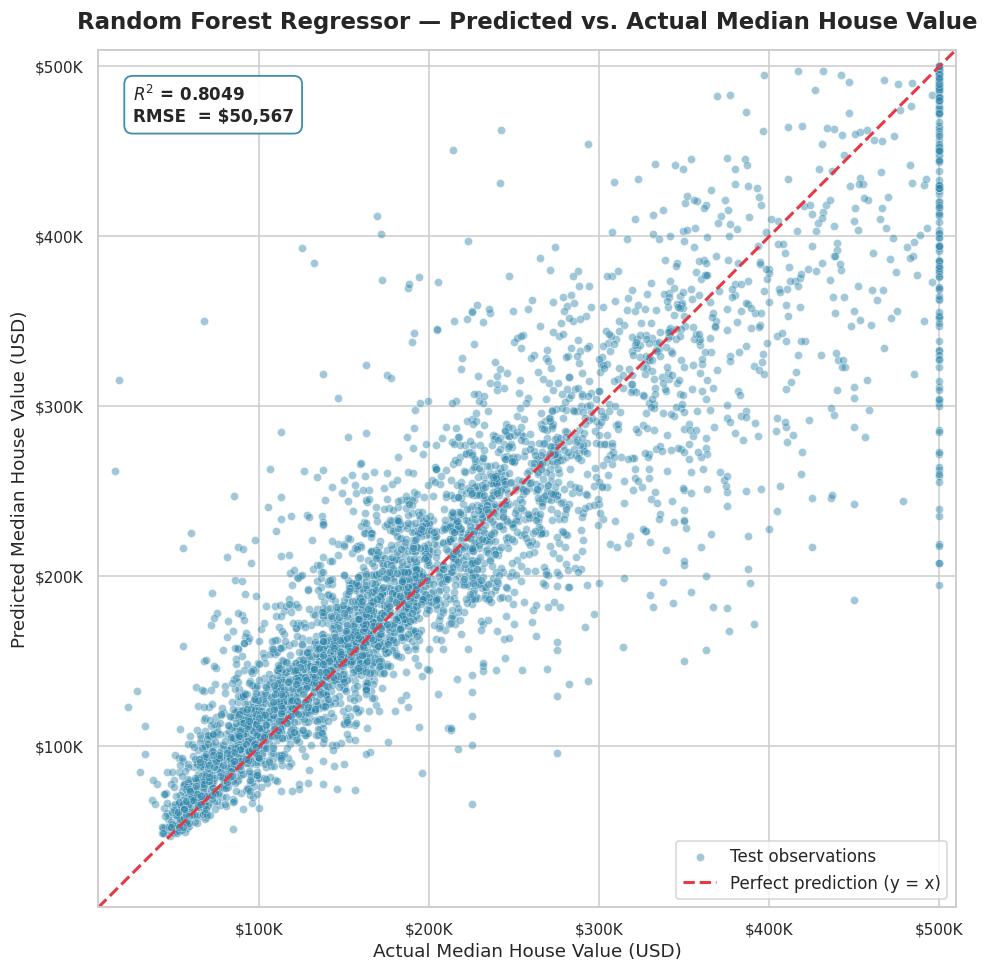

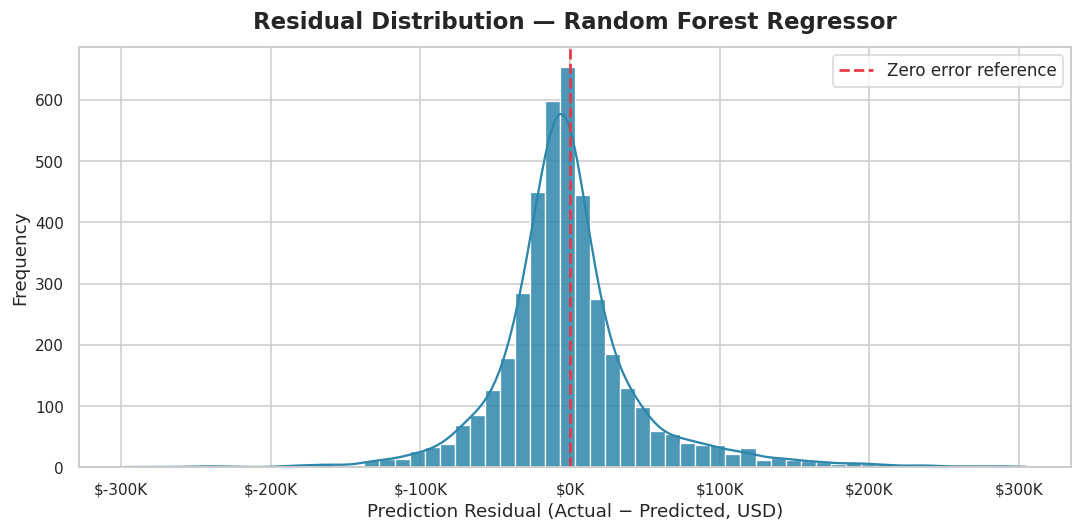

FINAL PROJECT SUMMARY — HOUSING PRICE PREDICTOR
Test partition size       : 4,128 observations
Best model                : Random Forest Regressor (n_estimators=100)
R-squared (R²)            : 0.8049   (80.49% variance explained)
Root Mean Squared Error   : 0.5057   (~ $50,567 USD average prediction error)
Mean absolute residual    : $32,803 USD
Median absolute residual  : $20,122 USD
Phase 6 complete — project ready for portfolio submission.


In [6]:
# ======================================================================
# PROJECT 2 — HOUSING PRICE PREDICTOR
# Phase 6: Final Results Visualization
# Author: Sebastian | Target: George Mason University (GMU) Portfolio
# Stack: Python 3 | NumPy | Pandas | Matplotlib | Seaborn
# ======================================================================
# Prerequisite: Phases 1 through 5 must have been executed in the
# current runtime so that the following objects already live in memory:
#   y_test, y_pred_rf, rmse_rf, r2_rf
# ======================================================================

# ----------------------------------------------------------------------
# 1. VISUAL CONFIGURATION
# ----------------------------------------------------------------------
# Reaffirm the corporate, presentation-ready theme to guarantee visual
# consistency with every previous figure rendered in this notebook.
sns.set_theme(style="whitegrid", palette="deep", context="notebook")

plt.rcParams.update({
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.dpi": 110,
})

# ----------------------------------------------------------------------
# 2. PREPARE PLOT DATA
# ----------------------------------------------------------------------
# Convert target and prediction vectors into native dollar units to
# produce a chart that is immediately interpretable for non-technical
# stakeholders (admissions reviewers, faculty, hiring managers).
actual_usd    = y_test.values * 100_000
predicted_usd = y_pred_rf      * 100_000

# Compute a symmetric axis range so the diagonal reference line and the
# scatter cloud share a single, balanced coordinate system.
plot_min = float(min(actual_usd.min(), predicted_usd.min()))
plot_max = float(max(actual_usd.max(), predicted_usd.max()))

# Apply a small padding so extreme points are not clipped against the
# edges of the plot area.
axis_padding = (plot_max - plot_min) * 0.02
axis_lo = plot_min - axis_padding
axis_hi = plot_max + axis_padding

# ----------------------------------------------------------------------
# 3. PREDICTION vs. ACTUAL SCATTER PLOT
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 9))

# Scatter cloud — alpha transparency handles the high overplotting
# density characteristic of a ~4,000-point test partition.
sns.scatterplot(
    x=actual_usd,
    y=predicted_usd,
    color="#2E86AB",
    edgecolor="white",
    s=28,
    alpha=0.45,
    ax=ax,
    label="Test observations",
)

# Diagonal reference line (y = x) — represents the locus of perfect
# predictions. The closer the scatter cloud hugs this line, the closer
# the model approaches an ideal regressor.
ax.plot(
    [axis_lo, axis_hi],
    [axis_lo, axis_hi],
    linestyle="--",
    linewidth=2.0,
    color="#E63946",
    label="Perfect prediction (y = x)",
)

# Lock both axes to the same range — this is critical, because any
# asymmetry between the x and y scales would visually distort how
# close the predictions are to the diagonal.
ax.set_xlim(axis_lo, axis_hi)
ax.set_ylim(axis_lo, axis_hi)
ax.set_aspect("equal", adjustable="box")

# Format both axes as USD currency for stakeholder-ready readability.
usd_formatter = plt.FuncFormatter(lambda x, _: f"${x/1000:,.0f}K")
ax.xaxis.set_major_formatter(usd_formatter)
ax.yaxis.set_major_formatter(usd_formatter)

# Titles and labels — academic / publication standard.
ax.set_title(
    "Random Forest Regressor — Predicted vs. Actual Median House Value",
    pad=14,
)
ax.set_xlabel("Actual Median House Value (USD)")
ax.set_ylabel("Predicted Median House Value (USD)")

# Embed the key performance metrics directly inside the figure so the
# chart remains self-explanatory when exported as a standalone asset.
metrics_text = (
    f"$R^2$ = {r2_rf:.4f}\n"
    f"RMSE  = ${rmse_rf * 100_000:,.0f}"
)
ax.text(
    0.04, 0.96,
    metrics_text,
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#2E86AB",
        linewidth=1.2,
        alpha=0.92,
    ),
)

ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 4. RESIDUAL DISTRIBUTION — COMPLEMENTARY DIAGNOSTIC
# ----------------------------------------------------------------------
# A residual histogram centered tightly around zero is the second
# canonical evidence of a well-calibrated regressor. Systematic skew or
# bimodality here would reveal structural bias that the scatter plot
# alone might hide.
residuals_usd = actual_usd - predicted_usd

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    residuals_usd,
    bins=60,
    kde=True,
    color="#2E86AB",
    edgecolor="white",
    alpha=0.85,
    ax=ax,
)

ax.axvline(
    0.0,
    color="#E63946",
    linestyle="--",
    linewidth=1.8,
    label="Zero error reference",
)

ax.set_title(
    "Residual Distribution — Random Forest Regressor",
    pad=12,
)
ax.set_xlabel("Prediction Residual (Actual − Predicted, USD)")
ax.set_ylabel("Frequency")
ax.xaxis.set_major_formatter(usd_formatter)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 5. FINAL EXECUTIVE SUMMARY
# ----------------------------------------------------------------------
print("=" * 70)
print("FINAL PROJECT SUMMARY — HOUSING PRICE PREDICTOR")
print("=" * 70)
print(f"Test partition size       : {len(y_test):,} observations")
print(f"Best model                : Random Forest Regressor (n_estimators=100)")
print(f"R-squared (R²)            : {r2_rf:.4f}   "
      f"({r2_rf * 100:.2f}% variance explained)")
print(f"Root Mean Squared Error   : {rmse_rf:.4f}   "
      f"(~ ${rmse_rf * 100_000:,.0f} USD average prediction error)")
print(f"Mean absolute residual    : ${np.mean(np.abs(residuals_usd)):,.0f} USD")
print(f"Median absolute residual  : ${np.median(np.abs(residuals_usd)):,.0f} USD")
print("=" * 70)
print("Phase 6 complete — project ready for portfolio submission.")
print("=" * 70)